<a href="https://colab.research.google.com/github/nickkhymenko/asteria-credit-risk-ml/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd

df = pd.read_csv("loan_applications.csv")

df.head()


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,100048,0,Cash loans,F,N,Y,0,202500.0,604152.0,29196.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0
2,100054,0,Cash loans,F,N,Y,0,99000.0,260640.0,26838.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
3,100076,0,Cash loans,M,Y,N,0,180000.0,315000.0,9679.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,100080,0,Revolving loans,F,N,N,1,157500.0,450000.0,22500.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0


In [ ]:

print("Number of applications:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of applications: 11639
Number of columns: 122


In [ ]:

print(df["TARGET"].value_counts())

print("\nPercentage:")
print(df["TARGET"].value_counts(normalize=True) * 100)


TARGET
0    10710
1      929
Name: count, dtype: int64

Percentage:
TARGET
0    92.018215
1     7.981785
Name: proportion, dtype: float64


In [ ]:

missing = df.isnull().mean() * 100

missing = missing.sort_values(ascending=False)

missing.head(15)


,0
COMMONAREA_MEDI,70.048973
COMMONAREA_MODE,70.048973
COMMONAREA_AVG,70.040381
NONLIVINGAPARTMENTS_MEDI,69.610791
NONLIVINGAPARTMENTS_MODE,69.610791
NONLIVINGAPARTMENTS_AVG,69.610791
LIVINGAPARTMENTS_AVG,68.536816
LIVINGAPARTMENTS_MODE,68.536816
LIVINGAPARTMENTS_MEDI,68.536816
FONDKAPREMONT_MODE,68.502449


In [ ]:

df[["AMT_INCOME_TOTAL", "AMT_CREDIT"]].describe()


,AMT_INCOME_TOTAL,AMT_CREDIT
count,1.163900e+04,1.163900e+04
mean,1.692979e+05,5.981833e+05
std,1.127145e+05,4.013610e+05
min,2.700000e+04,4.500000e+04
25%,1.125000e+05,2.700000e+05
50%,1.485000e+05,5.120640e+05
75%,2.025000e+05,8.100000e+05
max,6.750000e+06,3.150000e+06


In [ ]:

df.groupby("TARGET")[["AMT_INCOME_TOTAL", "AMT_CREDIT"]].median()


,AMT_INCOME_TOTAL,AMT_CREDIT
TARGET,,
0,153000.0,513531.0
1,135000.0,497520.0


In [ ]:

import numpy as np

df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] /
    df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

df.groupby("TARGET")["CREDIT_INCOME_RATIO"].median()


,CREDIT_INCOME_RATIO
TARGET,
0,3.24352
1,3.21080


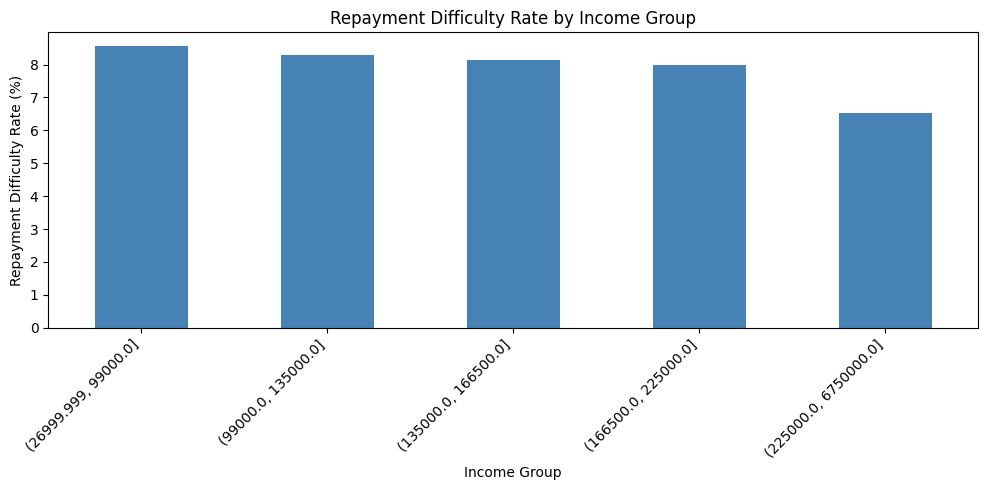

In [ ]:

import matplotlib.pyplot as plt

df["INCOME_GROUP"] = pd.qcut(
    df["AMT_INCOME_TOTAL"],
    q=5,
    duplicates="drop"
)

risk_by_income = (
    df.groupby("INCOME_GROUP", observed=True)["TARGET"]
    .mean() * 100
)

risk_by_income.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Repayment Difficulty Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Repayment Difficulty Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**EDA Finding 1 — Income and Repayment Difficulty**

The repayment difficulty rate generally decreases across higher income groups, from approximately 8.6% in the lowest income group to 6.5% in the highest. This suggests that applicant income may be associated with repayment risk and warrants further investigation during modelling.


In [ ]:

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25

df.groupby("TARGET")["AGE_YEARS"].median()


,AGE_YEARS
TARGET,
0,43.436003
1,39.039014


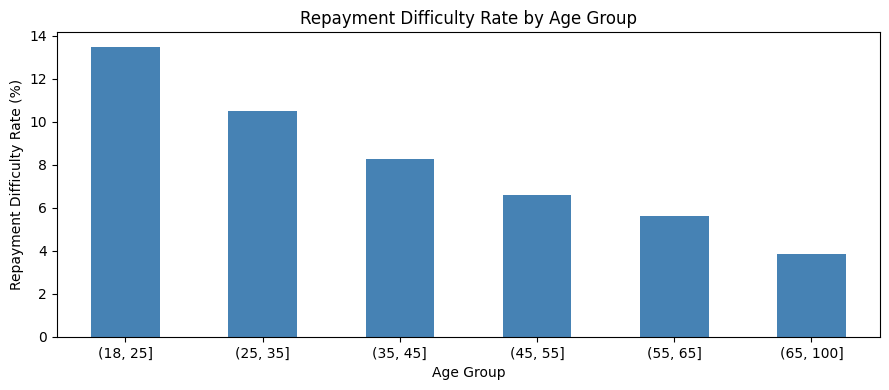

,mean,count
AGE_GROUP,,
"(18, 25]",0.134904,467
"(25, 35]",0.104842,2747
"(35, 45]",0.082750,3142
"(45, 55]",0.065726,2693
"(55, 65]",0.056399,2305
"(65, 100]",0.038596,285


In [ ]:

import matplotlib.pyplot as plt

df["AGE_GROUP"] = pd.cut(
    df["AGE_YEARS"],
    bins=[18, 25, 35, 45, 55, 65, 100]
)

age_risk = (
    df.groupby("AGE_GROUP", observed=True)["TARGET"]
    .agg(["mean", "count"])
)

age_risk["mean"].mul(100).plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue"
)

plt.title("Repayment Difficulty Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Repayment Difficulty Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_risk)


**EDA Finding 2 — Age and Repayment Difficulty**

Repayment difficulty rates decrease consistently across age groups, from 13.49% among applicants aged 18–25 to 3.86% among those over 65. The median age of applicants experiencing repayment difficulty is approximately 39 years, compared with 43 years for other applicants.

This indicates a notable association between age and repayment difficulty. However, further modelling is required to assess its predictive contribution, and any use of age in lending decisions would require fairness and regulatory consideration.

In [ ]:

import numpy as np

df["PAYMENT_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] /
    df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

df.groupby("TARGET")["PAYMENT_INCOME_RATIO"].median()


,PAYMENT_INCOME_RATIO
TARGET,
0,0.162100
1,0.164743


In [ ]:

print("Duplicate SK_ID_CURR:",
      df["SK_ID_CURR"].duplicated().sum())

print("Missing TARGET:",
      df["TARGET"].isna().sum())

print("Columns with missing values:",
      (df.isna().sum() > 0).sum())

print("Columns with over 50% missing:",
      (df.isna().mean() > 0.5).sum())

print("\nData types:")
print(df.dtypes.value_counts())


Duplicate SK_ID_CURR: 0
Missing TARGET: 0
Columns with missing values: 87
Columns with over 50% missing: 44

Data types:
float64     88
int64       21
object      16
category     1
category     1
Name: count, dtype: int64


In [ ]:

credit_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

df[credit_features].describe()


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,5043.000000,11612.000000,9273.000000
mean,0.500225,0.515169,0.509860
std,0.212559,0.192203,0.194133
min,0.022339,0.000030,0.000527
25%,0.332969,0.394729,0.368969
50%,0.506725,0.566662,0.533482
75%,0.669945,0.665204,0.667458
max,0.930797,0.855000,0.882530


In [ ]:

df.groupby("TARGET")[credit_features].median()


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
TARGET,,,
0,0.519429,0.573704,0.544235
1,0.331821,0.454735,0.372334


**EDA Finding 3 — External Credit Scores**

All three external score variables exhibit substantially lower median values among applicants experiencing repayment difficulty. EXT_SOURCE_1 has approximately 56.7% missing values, compared with 20.3% for EXT_SOURCE_3 and 0.2% for EXT_SOURCE_2.

These variables appear promising for repayment difficulty prediction. We will retain them for modelling, handle missing values within the training pipeline, and assess their predictive contribution during validation.

## EDA Summary — Asteria Finance

The initial exploratory analysis covers 11,639 loan applications and 122 original variables. Approximately 7.98% of applicants are labelled as experiencing repayment difficulty, indicating a substantial class imbalance.

The dataset contains no duplicate applicant identifiers or missing target values. However, missing data is widespread, with 44 original variables having more than 50% missing observations.

Repayment difficulty is associated with lower applicant income and younger age. All three external score variables show lower median values among applicants with repayment difficulty, suggesting potential predictive value.

Three features were engineered: applicant age in years, credit-to-income ratio and payment-to-income ratio.

**Next steps:** verify the complete development dataset, investigate additional relational tables, handle missing values and categorical variables, and compare classification models using stratified validation.